---
# **Facebook Network Analysis**
### Joseph Nicolas
---

## Imports

The necessary libraries required to run this notebook are below.

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms.community import louvain_communities, label_propagation_communities

---
## Task 1: Basic Network Metrics

The first step is to load the Facebook combined network and compute its essential properties: number of nodes and edges, density, and average degree. \
Then I can do a spring‑layout plot which gives a first visual impression of the structure.

Number of nodes: 4039
,Number of edges: 88234
,Network density: 0.010820
,Average degree: 43.69


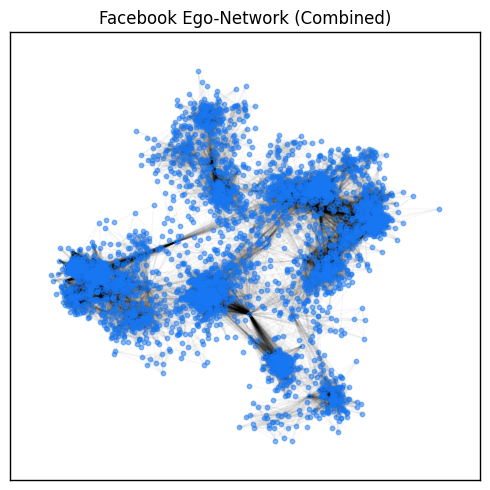

In [2]:
# Load the Facebook combined network (undirected), with some basic error handling
try:
    G = nx.read_edgelist('facebook_combined-1.txt', nodetype=int)
except FileNotFoundError:
    print("Error: 'facebook_combined-1.txt' not found. Please make sure it's in the current directory.")
    G = None
except Exception as err:
    print(f"Error loading network: {err}")
    G = None

if G is not None:
    # Basic metrics
    n_nodes = G.number_of_nodes()
    n_edges = G.number_of_edges()
    density = nx.density(G)
    avg_degree = np.mean([d for _, d in G.degree()])

    print(f"Number of nodes: {n_nodes}")
    print(f"Number of edges: {n_edges}")
    print(f"Network density: {density:.6f}")
    print(f"Average degree: {avg_degree:.2f}")

    # Visualise the network (spring layout, small nodes, no labels for clarity)
    fig, ax = plt.subplots(figsize=(5, 5))
    pos = nx.spring_layout(G, seed=50, k=0.3, iterations=50)
    nx.draw_networkx_nodes(G, pos, node_size=10, node_color='#1877F2', alpha=0.5)
    nx.draw_networkx_edges(G, pos, alpha=0.03)
    plt.title('Facebook Ego-Network (Combined)')

    # Set a black border around the plot to match the other plots so far
    for spine in ax.spines.values():
        spine.set_edgecolor('black')
        spine.set_linewidth(1)

    plt.tight_layout()
    plt.savefig('./facebook_network.png', dpi=600)
    plt.show()
else:
    print("Skipping network analysis and visualization.")

The network is read from `facebook_combined-1.txt` as an undirected graph, with a simple error check in case the file is missing.  
Metrics are printed directly: number of nodes, edges, density and average degree.  
The network density is very low, around 1.08%, because the graph is sparse. The average degree reflects that most users have only a few connections while a smaller number are highly connected.

The visualisation uses a spring layout with tiny nodes and semi‑transparent edges.  
Even at this scale it is clear there are a few dense clusters, but most groups are only loosely connected to one another.

---
## Task 2: Edge Centrality

We then calculate edge betweenness centrality for every edge and plot its distribution.\
This measure tells us which edges lie on the largest number of shortest paths, acting as bridges in the network.

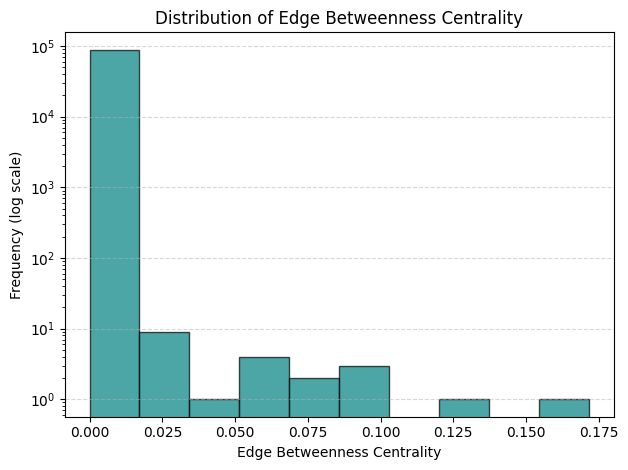

Edge centrality: min=0.0000, max=0.1715, mean=0.0000, median=0.0000


In [3]:
# Edge betweenness centrality (normalized)
edge_cent = nx.edge_betweenness_centrality(G, normalized=True)
cent_values = list(edge_cent.values())

# Plot histogram with log y-axis to be able to see all the values
plt.figure()
plt.hist(cent_values, color='teal', edgecolor='black', alpha=0.7, log=True)
plt.xlabel('Edge Betweenness Centrality')
plt.ylabel('Frequency (log scale)')
plt.title('Distribution of Edge Betweenness Centrality')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig('./edge_centrality_dist.png', dpi=600)
plt.show()

# Summary statistics
print(f"Edge centrality: min={np.min(cent_values):.4f}, max={np.max(cent_values):.4f}, "
      f"mean={np.mean(cent_values):.4f}, median={np.median(cent_values):.4f}")

The code runs `nx.edge_betweenness_centrality` with normalisation, then extracts the values into a list. The histogram uses a log‑scale y‑axis because the distribution is extremely skewed with nearly all edges have near‑zero centrality, while a tiny fraction carry much higher values. The summary statistics (min, max, mean, median) confirm this long‑tailed shape.

The few edges with high centrality are the ones that hold different communities together. If those high centrality communities are removed, the network would fragment. In a Facebook friendship graph, these likely correspond to people who connect otherwise separate social circles.

---
## Task 3: Community Detection

Lastly, we can now look for natural groupings in the network using two different algorithms: Louvain and Label Propagation.\
Comparing their results shows how the choice of method influences the communities we find.

Louvain: 16 communities
,Top 10 sizes (Louvain): [548, 535, 448, 432, 423, 350, 323, 237, 226, 206]
,
,Label Propagation: 44 communities
,Top 10 sizes (LP): [1030, 753, 547, 469, 226, 215, 198, 179, 60, 49]
,
,Modularity (Louvain): 0.8350


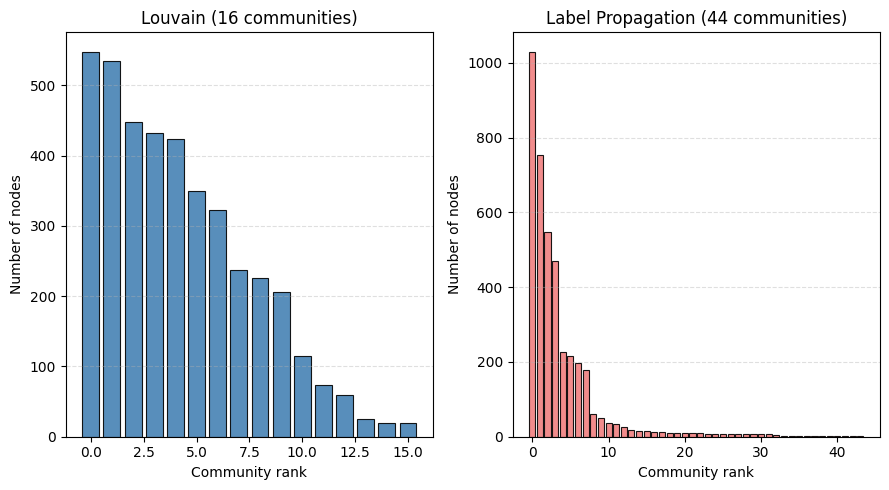

In [4]:
def community_stats(communities):
    """Return partition dict, size dict, and count from a list of community sets."""
    partition = {}
    sizes = {}
    for cid, nodes in enumerate(communities):
        sizes[cid] = len(nodes)
        for node in nodes:
            partition[node] = cid
    return partition, sizes, len(communities)

# Louvain
communities_louvain = louvain_communities(G, seed=50)
partition_louvain, sizes_louvain, n_louvain = community_stats(communities_louvain)
print(f"Louvain: {n_louvain} communities")
print(f"Top 10 sizes (Louvain): {sorted(sizes_louvain.values(), reverse=True)[:10]}")

# Label Propagation
communities_lp = label_propagation_communities(G)
partition_lp, sizes_lp, n_lp = community_stats(communities_lp)
print(f"\nLabel Propagation: {n_lp} communities")
print(f"Top 10 sizes (LP): {sorted(sizes_lp.values(), reverse=True)[:10]}")

# Modularity (Louvain)
mod_louvain = nx.community.modularity(G, communities_louvain)
print(f"\nModularity (Louvain): {mod_louvain:.4f}")

# Comparison plot
fig, axes = plt.subplots(1, 2, figsize=(9, 5))

# Louvain sizes
sorted_louvain = sorted(sizes_louvain.values(), reverse=True)
axes[0].bar(range(len(sorted_louvain)), sorted_louvain,
            color='steelblue', alpha=0.9, edgecolor='black', linewidth=0.8)
axes[0].set_title(f'Louvain ({n_louvain} communities)')
axes[0].set_xlabel('Community rank')
axes[0].set_ylabel('Number of nodes')
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

# Label Propagation sizes
sorted_lp = sorted(sizes_lp.values(), reverse=True)
axes[1].bar(range(len(sorted_lp)), sorted_lp,
            color='lightcoral', alpha=0.9, edgecolor='black', linewidth=0.8)
axes[1].set_title(f'Label Propagation ({n_lp} communities)')
axes[1].set_xlabel('Community rank')
axes[1].set_ylabel('Number of nodes')
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig('./community_comparison.png', dpi=600)
plt.show()

The helper function `community_stats` unpacks community sets into partition and size dictionaries, keeping the code clean.  

Louvain finds 16 communities. The size distribution decays gradually, with the largest communities being in the 400–550 range, and the smaller ones having aroun 20 nodes. \
Label Propagation finds 44 communities with a much steeper decline. After the first few large groups, sizes drop sharply, and beyond rank 10 the bars become not clearly visible on the plot.  

The Louvain modularity is 0.835, which is high and confirms a strong community structure. The two algorithms give different numeric splits, but both agree the network is not random and contains clear social groupings.

---
# End
---